## CS435/535 Performance - Fall 2026

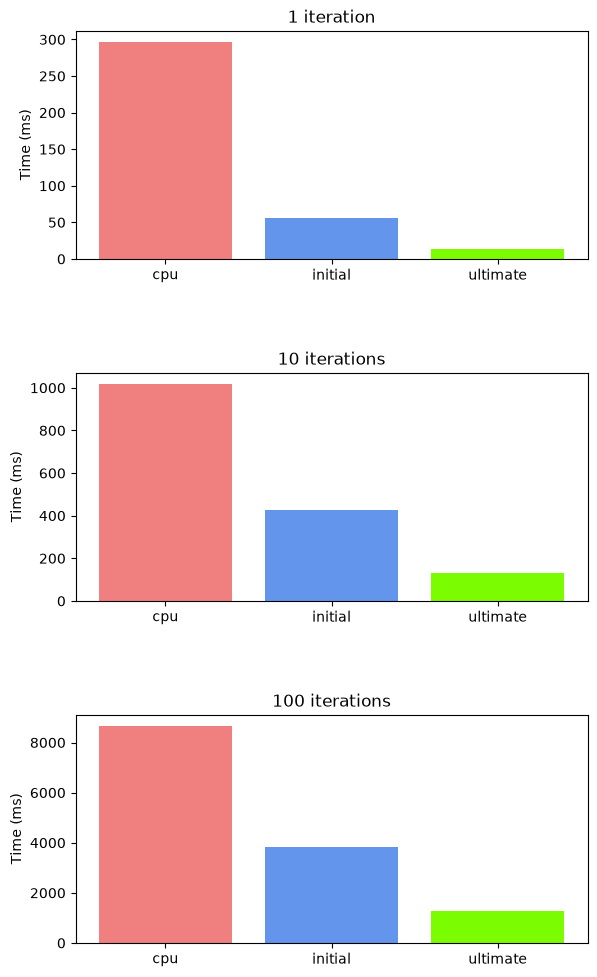

In [50]:
import matplotlib.pyplot as plt
import json

js = '[{"alg": 0, "iters": 1, "time": 296.795706}, {"alg": 0, "iters": 10, "time": 1018.871283}, {"alg": 0, "iters": 100, "time": 8668.452440}, {"alg": 1, "iters": 1, "time": 56.558208}, {"alg": 1, "iters": 10, "time": 425.135773}, {"alg": 1, "iters": 100, "time": 3826.624512}, {"alg": 15, "iters": 1, "time": 13.309728}, {"alg": 15, "iters": 10, "time": 129.594940}, {"alg": 15, "iters": 100, "time": 1282.196655}]'

d = json.loads(js)

# order by iterations -> algorithm -> time
data = {}
for item in d:
    if item['iters'] in data:
        data[item['iters']][str(item['alg'])] = item['time']
    else:
        data[item['iters']] = {str(item['alg']): item['time']}

# print(data)

fig, axs = plt.subplots(len(data))
fig.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=2, hspace=0.5, wspace=0.2)
for count, (k, v) in enumerate(data.items()):
    axs[count].set_title(f'{k} iteration{'s' if k > 1 else ''}')
    axs[count].bar(v.keys(), v.values(), color=['lightcoral', 'cornflowerblue', 'lawngreen'])
    axs[count].set_xticks([str(x) for x in v.keys()])
    axs[count].set_xticklabels(['cpu', 'initial', 'ultimate'])
    axs[count].set_ylabel('Time (ms)')

plt.show()
plt.close('all')


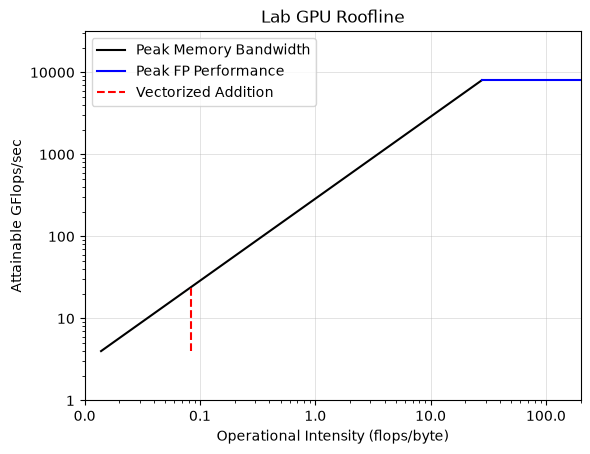

In [2]:
# | echo: false
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# graph limits
min_oi = 1./100
max_oi = 200
min_tflops = 1
max_tflops = 32000

bandwidth_line_scaling = 2000

nvidia_max = 8000 # 8 TFlop/s from documentation
mem_bw = 288 # 288 GB/s from documentation

ridge_point_x = nvidia_max/mem_bw
ridge_point_y = nvidia_max

fig, ax = plt.subplots()

plt.title("Lab GPU Roofline")
plt.xlabel('Operational Intensity (flops/byte)')
plt.ylabel('Attainable GFlops/sec')

# memory bandwidth constraint
plt.plot([ridge_point_x/bandwidth_line_scaling, ridge_point_x],
         [ridge_point_y/bandwidth_line_scaling, ridge_point_y], color='black')

# flops constraint
plt.plot([ridge_point_x, max_oi], [nvidia_max, nvidia_max], color='blue')

# vectorized addition utilization
plt.plot([1./12, 1./12], [ridge_point_y/bandwidth_line_scaling, 1./12 * mem_bw], '--r')

plt.grid(True)
plt.loglog()

# set these AFTER loglog
plt.axis((min_oi, max_oi, min_tflops, max_tflops))
ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())

plt.legend(['Peak Memory Bandwidth', 'Peak FP Performance', 'Vectorized Addition'],
           loc='upper left')

plt.show()


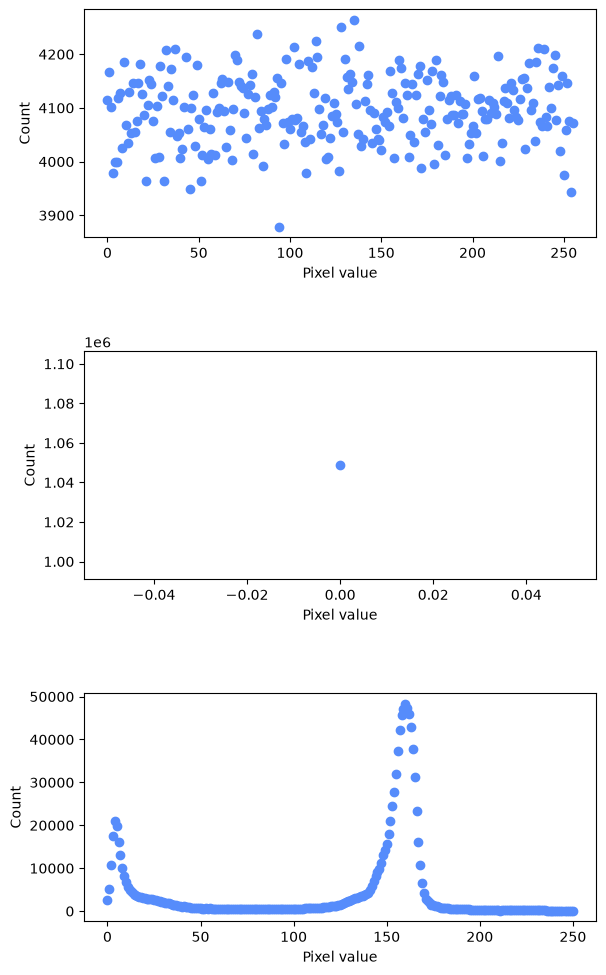

In [22]:
import numpy as np

x = '[{"rnd1mb":{"0": 4115, "1": 4167, "2": 4101, "3": 3978, "4": 3999, "5": 4000, "6": 4118, "7": 4128, "8": 4026, "9": 4186, "10": 4069, "11": 4034, "12": 4130, "13": 4054, "14": 4147, "15": 4056, "16": 4076, "17": 4147, "18": 4181, "19": 4126, "20": 4086, "21": 3964, "22": 4106, "23": 4152, "24": 4145, "25": 4076, "26": 4006, "27": 4104, "28": 4009, "29": 4178, "30": 4123, "31": 3963, "32": 4207, "33": 4141, "34": 4055, "35": 4172, "36": 4115, "37": 4209, "38": 4048, "39": 4054, "40": 4007, "41": 4023, "42": 4101, "43": 4194, "44": 4061, "45": 3949, "46": 4099, "47": 4125, "48": 4030, "49": 4180, "50": 4079, "51": 3963, "52": 4012, "53": 4065, "54": 4097, "55": 4005, "56": 4061, "57": 4015, "58": 4127, "59": 4013, "60": 4093, "61": 4099, "62": 4147, "63": 4154, "64": 4095, "65": 4028, "66": 4149, "67": 4058, "68": 4003, "69": 4098, "70": 4199, "71": 4189, "72": 4148, "73": 4141, "74": 4138, "75": 4091, "76": 4044, "77": 4126, "78": 4143, "79": 4164, "80": 4015, "81": 4121, "82": 4237, "83": 4062, "84": 4094, "85": 3991, "86": 4080, "87": 4068, "88": 4098, "89": 4125, "90": 4101, "91": 4130, "92": 4121, "93": 4156, "94": 3878, "95": 4147, "96": 4072, "97": 4032, "98": 4191, "99": 4073, "100": 4060, "101": 4079, "102": 4213, "103": 4077, "104": 4081, "105": 4182, "106": 4055, "107": 4067, "108": 4037, "109": 3978, "110": 4188, "111": 4043, "112": 4176, "113": 4127, "114": 4225, "115": 4195, "116": 4098, "117": 4052, "118": 4068, "119": 4119, "120": 4005, "121": 4008, "122": 4044, "123": 4085, "124": 4110, "125": 4089, "126": 4074, "127": 3982, "128": 4250, "129": 4056, "130": 4191, "131": 4157, "132": 4136, "133": 4163, "134": 4149, "135": 4264, "136": 4107, "137": 4051, "138": 4216, "139": 4030, "140": 4043, "141": 4112, "142": 4144, "143": 4161, "144": 4096, "145": 4034, "146": 4091, "147": 4061, "148": 4043, "149": 4041, "150": 4021, "151": 4084, "152": 4074, "153": 4093, "154": 4066, "155": 4168, "156": 4128, "157": 4006, "158": 4111, "159": 4099, "160": 4189, "161": 4175, "162": 4082, "163": 4147, "164": 4125, "165": 4009, "166": 4049, "167": 4144, "168": 4037, "169": 4125, "170": 4164, "171": 4178, "172": 3988, "173": 4080, "174": 4055, "175": 4152, "176": 4096, "177": 4070, "178": 4169, "179": 3996, "180": 4190, "181": 4031, "182": 4122, "183": 4162, "184": 4149, "185": 4012, "186": 4079, "187": 4115, "188": 4123, "189": 4086, "190": 4087, "191": 4124, "192": 4071, "193": 4112, "194": 4088, "195": 4088, "196": 4107, "197": 4007, "198": 4032, "199": 4053, "200": 4066, "201": 4159, "202": 4053, "203": 4116, "204": 4118, "205": 4094, "206": 4011, "207": 4080, "208": 4080, "209": 4115, "210": 4090, "211": 4110, "212": 4102, "213": 4088, "214": 4197, "215": 4002, "216": 4034, "217": 4112, "218": 4138, "219": 4110, "220": 4082, "221": 4146, "222": 4134, "223": 4096, "224": 4083, "225": 4078, "226": 4116, "227": 4153, "228": 4156, "229": 4023, "230": 4138, "231": 4184, "232": 4097, "233": 4110, "234": 4038, "235": 4186, "236": 4212, "237": 4073, "238": 4066, "239": 4209, "240": 4083, "241": 4066, "242": 4139, "243": 4100, "244": 4175, "245": 4198, "246": 4078, "247": 4143, "248": 4020, "249": 4160, "250": 3976, "251": 4059, "252": 4146, "253": 4076, "254": 3943, "255": 4072 },"zeros":{"0": 1048576 },"image.pgm":{"0": 2616, "1": 5081, "2": 10791, "3": 17523, "4": 20908, "5": 19844, "6": 16156, "7": 13110, "8": 10112, "9": 8158, "10": 6688, "11": 5579, "12": 4899, "13": 4348, "14": 4031, "15": 3751, "16": 3586, "17": 3303, "18": 3250, "19": 3167, "20": 3054, "21": 2944, "22": 2899, "23": 2865, "24": 2786, "25": 2617, "26": 2526, "27": 2426, "28": 2282, "29": 2201, "30": 2021, "31": 1984, "32": 1809, "33": 1784, "34": 1553, "35": 1509, "36": 1383, "37": 1336, "38": 1235, "39": 1170, "40": 1078, "41": 1081, "42": 918, "43": 876, "44": 860, "45": 777, "46": 730, "47": 710, "48": 717, "49": 722, "50": 648, "51": 605, "52": 579, "53": 632, "54": 586, "55": 624, "56": 540, "57": 551, "58": 527, "59": 507, "60": 516, "61": 495, "62": 447, "63": 465, "64": 417, "65": 448, "66": 466, "67": 451, "68": 396, "69": 422, "70": 414, "71": 451, "72": 394, "73": 417, "74": 423, "75": 406, "76": 444, "77": 455, "78": 448, "79": 455, "80": 497, "81": 505, "82": 480, "83": 455, "84": 450, "85": 468, "86": 422, "87": 414, "88": 414, "89": 425, "90": 438, "91": 411, "92": 420, "93": 438, "94": 496, "95": 448, "96": 480, "97": 497, "98": 448, "99": 451, "100": 489, "101": 470, "102": 516, "103": 492, "104": 608, "105": 614, "106": 647, "107": 618, "108": 705, "109": 715, "110": 670, "111": 715, "112": 710, "113": 784, "114": 766, "115": 824, "116": 903, "117": 930, "118": 958, "119": 1066, "120": 1245, "121": 1261, "122": 1290, "123": 1280, "124": 1363, "125": 1509, "126": 1716, "127": 1989, "128": 2187, "129": 2296, "130": 2477, "131": 2649, "132": 2733, "133": 2978, "134": 3168, "135": 3378, "136": 3621, "137": 3603, "138": 3823, "139": 4109, "140": 4229, "141": 4970, "142": 5856, "143": 6963, "144": 8083, "145": 9048, "146": 9836, "147": 11236, "148": 12994, "149": 14285, "150": 15641, "151": 17988, "152": 21055, "153": 24528, "154": 27655, "155": 32060, "156": 37392, "157": 42251, "158": 45688, "159": 47147, "160": 48299, "161": 47377, "162": 45996, "163": 42943, "164": 37877, "165": 31175, "166": 23250, "167": 16067, "168": 10697, "169": 6588, "170": 4200, "171": 2889, "172": 2275, "173": 1816, "174": 1534, "175": 1354, "176": 1212, "177": 1093, "178": 948, "179": 812, "180": 756, "181": 736, "182": 623, "183": 641, "184": 583, "185": 564, "186": 499, "187": 487, "188": 499, "189": 540, "190": 575, "191": 515, "192": 515, "193": 478, "194": 405, "195": 327, "196": 309, "197": 276, "198": 276, "199": 226, "200": 211, "201": 184, "202": 170, "203": 208, "204": 179, "205": 201, "206": 201, "207": 168, "208": 166, "209": 163, "210": 165, "211": 140, "212": 150, "213": 198, "214": 175, "215": 185, "216": 193, "217": 176, "218": 185, "219": 177, "220": 217, "221": 202, "222": 182, "223": 208, "224": 209, "225": 206, "226": 175, "227": 222, "228": 211, "229": 190, "230": 183, "231": 204, "232": 181, "233": 196, "234": 173, "235": 154, "236": 134, "237": 117, "238": 66, "239": 46, "240": 20, "241": 13, "242": 7, "243": 3, "244": 3, "246": 2, "247": 1, "248": 2, "249": 1, "250": 1 }}]'

histo_data = json.loads(x)

# order by type -> x -> y
data = {}
for fname in histo_data[0]:
    data[fname] = ([int(z) for z in histo_data[0][fname].keys()], [int(z) for z in histo_data[0][fname].values()])

fig, axs = plt.subplots(len(data))
fig.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=2, hspace=0.5, wspace=0.2)
for count, (name, v) in enumerate(data.items()):
    # axs[count].set_title(f'{k} iteration{'s' if k > 1 else ''}')
    axs[count].scatter(v[0], v[1])
    axs[count].set_ylabel('Count')
    axs[count].set_xlabel('Pixel value')




{'zeros': {'0': {'iters': 100, 'time': 85.690315}, '1': {'iters': 100, 'time': 92.79724884033203}, '15': {'iters': 100, 'time': 15.445952415466309}}, 'rnd1mb': {'0': {'iters': 100, 'time': 87.550872}, '1': {'iters': 100, 'time': 46.25600051879883}, '15': {'iters': 100, 'time': 15.006976127624512}}, 'image.pgm': {'0': {'iters': 100, 'time': 94.790426}, '1': {'iters': 100, 'time': 50.39052963256836}, '15': {'iters': 100, 'time': 14.974143981933594}}}


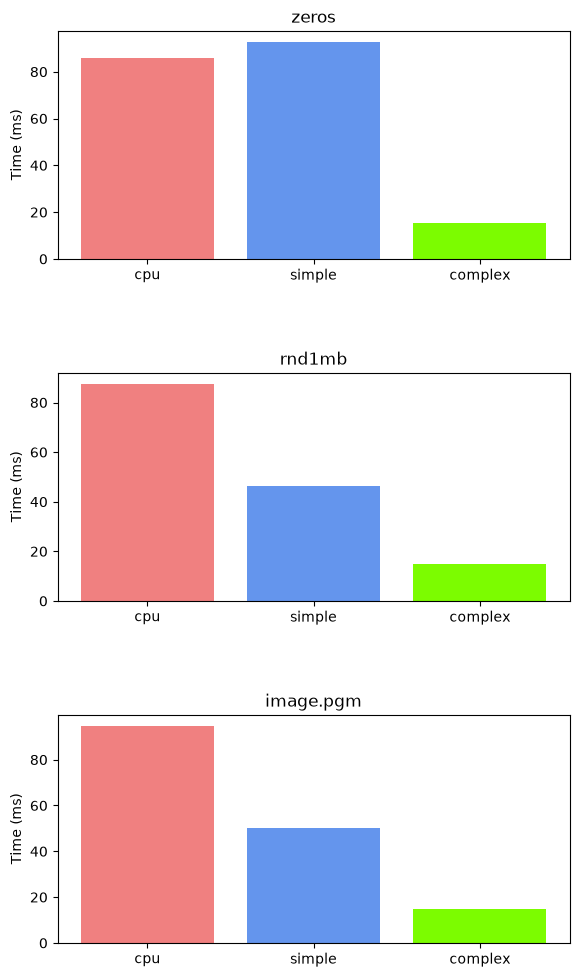

In [60]:
# trying out new JSON output scheme
# experiment -> result - array of bin values
#            -> meta - details

time_by_image = {}
desired_iters = 100
with (open('test.json') as r):
    data = json.load(r)

    for experiment in data:
        # print(experiment)
        if 'meta' in data[experiment]:
            m = data[experiment]['meta']
            if m["iters"] != 100:
                continue
            if m["fname"] not in time_by_image:
                time_by_image[m["fname"]] = {}
            time_by_image[m["fname"]][str(m["algo"])] = {"iters": m["iters"], "time": data[experiment]["timeMs"]}

print(time_by_image)

fig, axs = plt.subplots(len(time_by_image))
fig.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=2, hspace=0.5, wspace=0.2)
for count, (k, v) in enumerate(time_by_image.items()):
    axs[count].set_title(f'{k}')
    axs[count].bar(v.keys(), [x['time'] for x in v.values()], color=['lightcoral', 'cornflowerblue', 'lawngreen'])
    axs[count].set_xticks(ticks= [x for x in v.keys()], labels=['cpu', 'simple', 'complex'])
    # axs[count].set_xticklabels(['cpu', 'initial', 'ultimate'])
    axs[count].set_ylabel('Time (ms)')

plt.show()
plt.close('all')
